In [1]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import polars as pl
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)


import arbitrage
import black_scholes
import ekf
import events
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.plots as plots
import personal.shared_functions.utils as utils
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [3]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

## Build combined IV surface — calls and puts together

In [4]:
imp.reload(ekf)
imp.reload(events)
imp.reload(kalman_filters)
imp.reload(utils)

<module 'personal.shared_functions.utils' from '/Users/elie/Documents/GitHub/quant_data/personal/shared_functions/utils.py'>

In [5]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_iv_surface_long = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)
df_iv_surface_long

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
Skipping O:SPY240105C00481000: 46 bad quotes (sub-tick bid×46)
Skipping O:SPY240105C00482000: 64 bad quotes (sub-tick bid×64)
Skipping O:SPY240105C00483000: 842 bad quotes (sub-tick bid×842, zero bid size×1)
Skipping O:SPY240105C00484000: 2129 bad quotes (sub-tick bid×2129, zero bid size×1)
Skipping O:SPY240105C00485000: 3888 bad quotes (sub-tick bid×3888, zero bid size×2)
O:SPY240105P00450000: dropping 1 bad quote

(shape: (2_137_388, 7)
 ┌───────────────────────────────┬─────────────┬──────────┬──────────┬───────────┬────────┬─────────┐
 │ ts_ns                         ┆ observed_iv ┆ bid_iv   ┆ ask_iv   ┆ kalman_iv ┆ strike ┆ is_call │
 │ ---                           ┆ ---         ┆ ---      ┆ ---      ┆ ---       ┆ ---    ┆ ---     │
 │ datetime[ns,                  ┆ f64         ┆ f64      ┆ f64      ┆ f64       ┆ f64    ┆ bool    │
 │ America/New_York]             ┆             ┆          ┆          ┆           ┆        ┆         │
 ╞═══════════════════════════════╪═════════════╪══════════╪══════════╪═══════════╪════════╪═════════╡
 │ 2024-01-03 09:30:00.006781440 ┆ null        ┆ null     ┆ null     ┆ null      ┆ 479.0  ┆ true    │
 │ …                             ┆             ┆          ┆          ┆           ┆        ┆         │
 │ 2024-01-03 09:30:00.008294144 ┆ null        ┆ null     ┆ null     ┆ null      ┆ 471.0  ┆ false   │
 │ …                             ┆             ┆          ┆

In [6]:
print("Calls:", df_iv_surface_long.filter(pl.col("is_call"))["strike"].n_unique(), "strikes")
print("Puts: ", df_iv_surface_long.filter(~pl.col("is_call"))["strike"].n_unique(), "strikes")

AttributeError: 'tuple' object has no attribute 'filter'

In [ ]:
# Wide format: columns are bid_iv_<strike>_C / bid_iv_<strike>_P etc.
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_iv_surface_wide

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,bid_iv_466_P,ask_iv_466_P,kalman_iv_466_P,…,kalman_iv_473_P,bid_iv_473_C,ask_iv_473_C,kalman_iv_473_C,bid_iv_474_P,ask_iv_474_P,kalman_iv_474_P,bid_iv_474_C,ask_iv_474_C,kalman_iv_474_C,bid_iv_475_P,ask_iv_475_P,kalman_iv_475_P,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008294144 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008340992 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008425216 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008504576 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.239235840 EST,0.231509,0.243399,0.237089,0.01,0.283903,0.113987,0.162586,0.167474,0.165325,0.159112,0.163074,0.159929,0.152652,0.155775,0.154131,0.149513,0.151922,0.150849,0.145428,0.147372,0.147253,0.143185,0.144725,0.144352,0.141786,0.143024,0.142068,0.139728,0.140756,0.139742,0.135979,0.146265,0.140691,0.137977,0.138868,0.13842,…,0.134029,0.132425,0.134495,0.132946,0.132673,0.143631,0.139446,0.131978,0.133294,0.13316,0.109112,0.172159,0.149118,0.131947,0.1336

In [ ]:
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_filtered.shape[0]:,} rows with no nulls / NaNs out of {df_iv_surface_wide.shape[0]:,}")

2,078,924 rows with no nulls / NaNs out of 2,079,349


## Smile snapshot — calls and puts on the same chart

In [ ]:
import personal.shared_functions.utils as _u

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

## OTM smile — puts left wing, calls right wing

In [ ]:
# Use the last available SPY price from the snapshot row as the ATM level.
# Below ATM: use put IVs (OTM puts).  Above ATM: use call IVs (OTM calls).

spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    if k <= spy_mid and f"kalman_iv_{K_int}_P" in row.columns:
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        otm_bid.append(row[f"bid_iv_{K_int}_P"][0])
        otm_ask.append(row[f"ask_iv_{K_int}_P"][0])
    elif k > spy_mid and f"kalman_iv_{K_int}_C" in row.columns:
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
        otm_bid.append(row[f"bid_iv_{K_int}_C"][0])
        otm_ask.append(row[f"ask_iv_{K_int}_C"][0])
    else:
        otm_mid.append(None)
        otm_bid.append(None)
        otm_ask.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [ ]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [ ]:
type(otm_bid)

list

In [ ]:
bid_array = np.array(otm_bid, dtype=np.float64)
bid_array = bid_array[~np.isnan(bid_array)]

In [ ]:
ask_array = np.array(otm_ask, dtype=np.float64)
ask_array = ask_array[~np.isnan(ask_array)]

In [ ]:
ask_array - bid_array

array([0.01200792, 0.26911943, 0.00504144, 0.00433211, 0.00341391,
       0.00290546, 0.00231199, 0.00186341, 0.00148877, 0.00121475,
       0.00101375, 0.00087447, 0.00078136, 0.00072542, 0.00070015,
       0.00036686, 0.00074108, 0.00081392, 0.00053251, 0.00112222,
       0.00140601, 0.00180503, 0.00251699, 0.00327621, 0.00426728])

## Arbitrage check — OTM surface

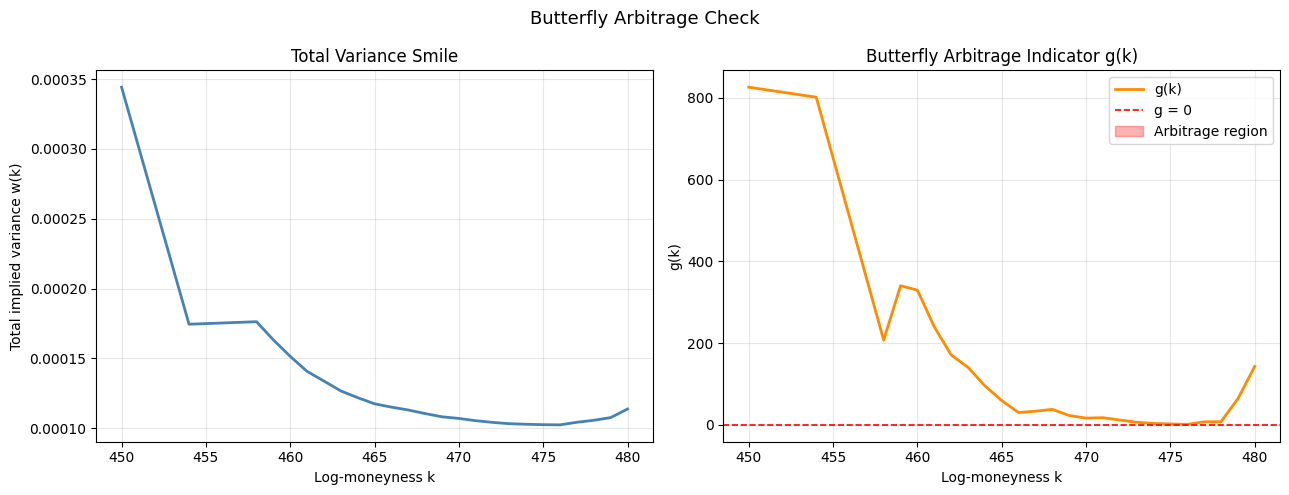

{'is_arbitrage_free': True,
 'min_g': 1.0338088089799249,
 'violations': array([], dtype=float64),
 'g': array([825.82070654, 801.42526058, 207.13513532, 340.29011718,
        329.31947393, 239.76456276, 171.19107154, 140.66688781,
         95.64300364,  59.32253353,  30.10872101,  33.32695007,
         37.8066541 ,  22.81036824,  16.49633251,  17.42242465,
         11.79471971,   6.33262979,   3.34120733,   2.20679531,
          1.03380881,   7.43709996,   7.74625916,  63.62209542,
        142.84969527]),
 'w': array([0.00034424, 0.0001745 , 0.0001763 , 0.0001633 , 0.00015147,
        0.00014071, 0.00013379, 0.00012672, 0.0001219 , 0.00011749,
        0.00011512, 0.00011306, 0.0001105 , 0.00010819, 0.00010702,
        0.00010541, 0.00010418, 0.00010326, 0.00010285, 0.00010254,
        0.00010243, 0.00010427, 0.00010569, 0.00010762, 0.00011376]),
 'k': array([450., 454., 458., 459., 460., 461., 462., 463., 464., 465., 466.,
        467., 468., 469., 470., 471., 472., 473., 474., 475., 

In [ ]:
tte = (expiry - snapshot_ts).total_seconds() / (365.25 * 24 * 3600)
valid_mask = [v is not None for v in otm_mid]
otm_strikes_v = [k for k, m in zip(otm_strikes, valid_mask) if m]
otm_mid_v = [v for v in otm_mid if v is not None]

arbitrage.check_butterfly(k=otm_strikes_v, iv=otm_mid_v, T=tte, plot=True)

In [ ]:
# Scan every 100th row in the fully-non-null subset for butterfly arbitrage.
n_arb = 0
for i in range(0, df_filtered.shape[0], 100):
    row_i = df_filtered[i]
    ts_i = row_i["ts_ns"][0]
    spy_i = df_spy.filter(pl.col("ts_ns") <= ts_i)["price"][-1]
    tte_i = float((expiry - ts_i).total_seconds()) / (365.25 * 24 * 3600)

    mid_i = []
    k_i = []
    for k in otm_strikes:
        K_int = int(k)
        col = f"kalman_iv_{K_int}_{'P' if k <= spy_i else 'C'}"
        if col in row_i.columns and row_i[col][0] is not None:
            mid_i.append(row_i[col][0])
            k_i.append(k)

    if len(k_i) < 3:
        continue
    result = arbitrage.check_butterfly(k=k_i, iv=mid_i, T=tte_i, plot=False)
    if not result["is_arbitrage_free"]:
        n_arb += 1
        print(f"Arbitrage at index {i} ({ts_i})")

print(
    f"\nTotal arbitrage violations: {n_arb} / {df_filtered.shape[0] // 100 + 1} snapshots checked"
)


Total arbitrage violations: 0 / 20790 snapshots checked


## IV vs Spot

In [ ]:
df_spy

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728
…,…,…,…
2024-01-03 19:59:57.242399488 EST,469.35,100.0,8192
2024-01-03 19:59:57.242399488 EST,469.35,400.0,8192
2024-01-03 19:59:58.998797568 EST,469.355,1.0,73728


In [ ]:
df_iv_surface_wide

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,bid_iv_466_P,ask_iv_466_P,kalman_iv_466_P,…,kalman_iv_473_P,bid_iv_473_C,ask_iv_473_C,kalman_iv_473_C,bid_iv_474_P,ask_iv_474_P,kalman_iv_474_P,bid_iv_474_C,ask_iv_474_C,kalman_iv_474_C,bid_iv_475_P,ask_iv_475_P,kalman_iv_475_P,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008294144 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008340992 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008425216 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
2024-01-03 09:30:00.008504576 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.239235840 EST,0.231509,0.243399,0.237089,0.01,0.283903,0.113987,0.162586,0.167474,0.165325,0.159112,0.163074,0.159929,0.152652,0.155775,0.154131,0.149513,0.151922,0.150849,0.145428,0.147372,0.147253,0.143185,0.144725,0.144352,0.141786,0.143024,0.142068,0.139728,0.140756,0.139742,0.135979,0.146265,0.140691,0.137977,0.138868,0.13842,…,0.134029,0.132425,0.134495,0.132946,0.132673,0.143631,0.139446,0.131978,0.133294,0.13316,0.109112,0.172159,0.149118,0.131947,0.1336

In [ ]:
df_with_spot = df_iv_surface_wide.sort("ts_ns").join_asof(
    df_spy.sort("ts_ns").select(["ts_ns", "price"]).rename({"price": "spot"}),
    on="ts_ns",
    strategy="backward",
)

In [ ]:
df_with_spot

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,bid_iv_466_P,ask_iv_466_P,kalman_iv_466_P,…,bid_iv_473_C,ask_iv_473_C,kalman_iv_473_C,bid_iv_474_P,ask_iv_474_P,kalman_iv_474_P,bid_iv_474_C,ask_iv_474_C,kalman_iv_474_C,bid_iv_475_P,ask_iv_475_P,kalman_iv_475_P,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,spot
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,470.46
2024-01-03 09:30:00.008294144 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,470.46
2024-01-03 09:30:00.008340992 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,470.46
2024-01-03 09:30:00.008425216 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,470.46
2024-01-03 09:30:00.008504576 EST,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,470.46
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.239235840 EST,0.231509,0.243399,0.237089,0.01,0.283903,0.113987,0.162586,0.167474,0.165325,0.159112,0.163074,0.159929,0.152652,0.155775,0.154131,0.149513,0.151922,0.150849,0.145428,0.147372,0.147253,0.143185,0.144725,0.144352,0.141786,0.143024,0.142068,0.139728,0.140756,0.139742,0.135979,0.146265,0.140691,0.137977,0.138868,0.13842,…,0.132425,0.134495,0.132946,0.132673,0.143631,0.139446,0.131978,0.133294,0.13316,0.109112,0.172159,0.149118,0.131947,0.133612,0.13289

In [ ]:
corr = df_with_spot.select(
    [
        pl.corr(col, "spot").alias(col)
        for col in df_with_spot.columns
        if col not in ("ts_ns", "spot")
    ]
)
corr

bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,bid_iv_466_P,ask_iv_466_P,kalman_iv_466_P,bid_iv_466_C,…,kalman_iv_473_P,bid_iv_473_C,ask_iv_473_C,kalman_iv_473_C,bid_iv_474_P,ask_iv_474_P,kalman_iv_474_P,bid_iv_474_C,ask_iv_474_C,kalman_iv_474_C,bid_iv_475_P,ask_iv_475_P,kalman_iv_475_P,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.778716,0.79804,0.831078,0.005999,0.359722,-0.02782,0.789388,0.862119,0.884222,0.806272,0.869519,0.87171,0.800259,0.858701,0.844765,0.732963,0.806418,0.788483,0.669281,0.744618,0.714627,0.563919,0.64579,0.617343,0.452449,0.53332,0.49773,0.348556,0.407605,0.373117,-0.112297,0.341612,0.310202,0.242147,0.279761,0.261446,-0.136578,…,-0.478561,-0.444716,-0.458933,-0.451799,-0.183165,-0.602872,-0.639489,-0.535388,-0.566953,-0.54884,-0.100006,-0.739214,-0.753196,-0.606214,-0.654806,-0.629527,0.124829,-0.672965,-0.909506,-0.608877,-0.688509,-0.657171,0.19005,-0.687777,-0.889166,-0.584064,-0.717383,-0.671325,-0.604086,-0.738568,-0.685797,-0.674108,-0.809383,-0.737447,-0.733017,-0.865018,-0.805774


In [ ]:
corr.select(cs.contains("kalman_iv"))

kalman_iv_450_P,kalman_iv_454_C,kalman_iv_458_P,kalman_iv_459_P,kalman_iv_460_P,kalman_iv_461_P,kalman_iv_462_P,kalman_iv_463_P,kalman_iv_464_P,kalman_iv_465_P,kalman_iv_465_C,kalman_iv_466_P,kalman_iv_466_C,kalman_iv_467_P,kalman_iv_467_C,kalman_iv_468_P,kalman_iv_468_C,kalman_iv_469_P,kalman_iv_469_C,kalman_iv_470_P,kalman_iv_470_C,kalman_iv_471_P,kalman_iv_471_C,kalman_iv_472_P,kalman_iv_472_C,kalman_iv_473_P,kalman_iv_473_C,kalman_iv_474_P,kalman_iv_474_C,kalman_iv_475_P,kalman_iv_475_C,kalman_iv_476_P,kalman_iv_476_C,kalman_iv_477_P,kalman_iv_477_C,kalman_iv_478_C,kalman_iv_479_C,kalman_iv_480_C
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.831078,-0.02782,0.884222,0.87171,0.844765,0.788483,0.714627,0.617343,0.49773,0.373117,0.310202,0.261446,0.237272,0.149066,0.127386,0.046429,0.054342,-0.045153,-0.029191,-0.13212,-0.111798,-0.235862,-0.206499,-0.355947,-0.332513,-0.478561,-0.451799,-0.639489,-0.54884,-0.753196,-0.629527,-0.909506,-0.657171,-0.889166,-0.671325,-0.685797,-0.737447,-0.805774


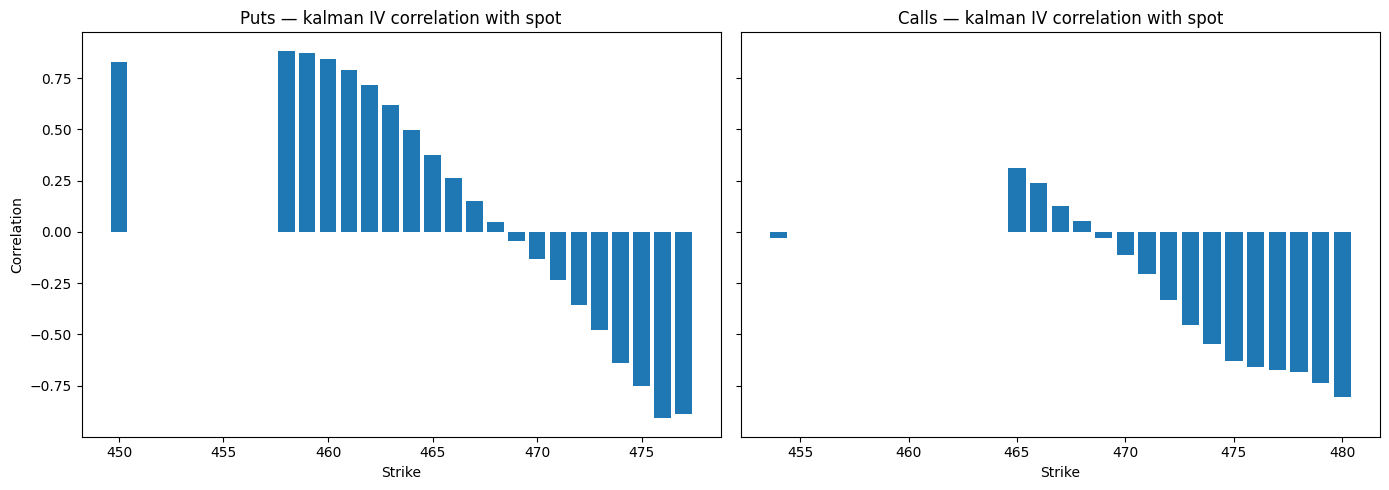

In [ ]:
corr_kalman = corr.select(cs.contains("kalman"))

puts = corr_kalman.select(cs.ends_with("_P")).unpivot(variable_name="column", value_name="corr")
calls = corr_kalman.select(cs.ends_with("_C")).unpivot(variable_name="column", value_name="corr")


# extract strike as numeric for x-axis
def extract_strike(df):
    return df.with_columns(
        pl.col("column").str.extract(r"(\d+)_[CP]$").cast(pl.Float64).alias("strike")
    ).sort("strike")


puts = extract_strike(puts)
calls = extract_strike(calls)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax1.bar(puts["strike"].to_list(), puts["corr"].to_list(), width=0.8)
ax1.set_title("Puts — kalman IV correlation with spot")
ax1.set_xlabel("Strike")
ax1.set_ylabel("Correlation")

ax2.bar(calls["strike"].to_list(), calls["corr"].to_list(), width=0.8)
ax2.set_title("Calls — kalman IV correlation with spot")
ax2.set_xlabel("Strike")

plt.tight_layout()
plt.show()

In [ ]:
df_price_surface_wide = utils.synchronize_price_surface(df_iv_surface_long)
df_price_surface_with_spot = df_price_surface_wide.sort("ts_ns").join_asof(
    df_spy.sort("ts_ns").select(["ts_ns", "price"]).rename({"price": "spot"}),
    on="ts_ns",
    strategy="backward",
)

In [ ]:
corr_price = df_price_surface_with_spot.select(
    [
        pl.corr(col, "spot").alias(col)
        for col in df_price_surface_with_spot.columns
        if col not in ("ts_ns", "spot")
    ]
)
corr_price

bid_price_450_P,ask_price_450_P,observed_price_450_P,bid_price_454_C,ask_price_454_C,observed_price_454_C,bid_price_458_P,ask_price_458_P,observed_price_458_P,bid_price_459_P,ask_price_459_P,observed_price_459_P,bid_price_460_P,ask_price_460_P,observed_price_460_P,bid_price_461_P,ask_price_461_P,observed_price_461_P,bid_price_462_P,ask_price_462_P,observed_price_462_P,bid_price_463_P,ask_price_463_P,observed_price_463_P,bid_price_464_P,ask_price_464_P,observed_price_464_P,bid_price_465_P,ask_price_465_P,observed_price_465_P,bid_price_465_C,ask_price_465_C,observed_price_465_C,bid_price_466_P,ask_price_466_P,observed_price_466_P,bid_price_466_C,…,observed_price_473_P,bid_price_473_C,ask_price_473_C,observed_price_473_C,bid_price_474_P,ask_price_474_P,observed_price_474_P,bid_price_474_C,ask_price_474_C,observed_price_474_C,bid_price_475_P,ask_price_475_P,observed_price_475_P,bid_price_475_C,ask_price_475_C,observed_price_475_C,bid_price_476_P,ask_price_476_P,observed_price_476_P,bid_price_476_C,ask_price_476_C,observed_price_476_C,bid_price_477_P,ask_price_477_P,observed_price_477_P,bid_price_477_C,ask_price_477_C,observed_price_477_C,bid_price_478_C,ask_price_478_C,observed_price_478_C,bid_price_479_C,ask_price_479_C,observed_price_479_C,bid_price_480_C,ask_price_480_C,observed_price_480_C
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-0.07722,-0.075291,-0.137523,0.933576,0.950599,0.972422,-0.485833,-0.480541,-0.489089,-0.537723,-0.537846,-0.549083,-0.641434,-0.64054,-0.647313,-0.711264,-0.710535,-0.71568,-0.771064,-0.770978,-0.77351,-0.822543,-0.822476,-0.821532,-0.860543,-0.860514,-0.861179,-0.890218,-0.890064,-0.890786,0.976318,0.985838,0.986995,-0.914694,-0.914529,-0.914814,0.982128,…,-0.987383,0.941302,0.941044,0.94139,-0.98255,-0.987366,-0.989155,0.9325,0.932485,0.932992,-0.982846,-0.989667,-0.990977,0.923718,0.923542,0.924746,-0.972574,-0.981471,-0.989861,0.911674,0.912227,0.913546,-0.96912,-0.982449,-0.988812,0.88755,0.891314,0.893981,0.857462,0.857664,0.86955,0.802258,0.802203,0.828085,0.730207,0.730749,0.775683


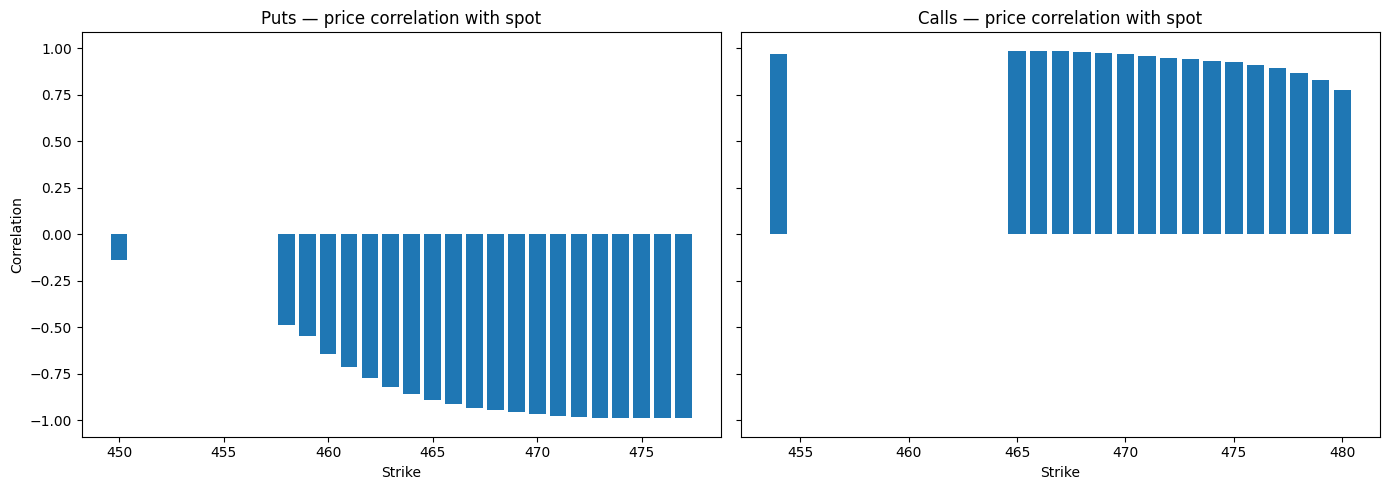

In [ ]:
corr_price_kalman = corr_price.select(cs.contains("observed"))

puts = corr_price_kalman.select(cs.ends_with("_P")).unpivot(
    variable_name="column", value_name="corr"
)
calls = corr_price_kalman.select(cs.ends_with("_C")).unpivot(
    variable_name="column", value_name="corr"
)


# extract strike as numeric for x-axis
def extract_strike(df):
    return df.with_columns(
        pl.col("column").str.extract(r"(\d+)_[CP]$").cast(pl.Float64).alias("strike")
    ).sort("strike")


puts = extract_strike(puts)
calls = extract_strike(calls)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax1.bar(puts["strike"].to_list(), puts["corr"].to_list(), width=0.8)
ax1.set_title("Puts — price correlation with spot")
ax1.set_xlabel("Strike")
ax1.set_ylabel("Correlation")

ax2.bar(calls["strike"].to_list(), calls["corr"].to_list(), width=0.8)
ax2.set_title("Calls — price correlation with spot")
ax2.set_xlabel("Strike")

plt.tight_layout()
plt.show()